<a href="https://colab.research.google.com/github/160423737030-lab/Codveda-Machine-Learning-Internship/blob/main/level2_task2_Decisiontree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (150, 5)
Target Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Missing Values: 0

--- Unpruned Decision Tree ---
Train Accuracy: 1.0000
Test Accuracy:  0.9333
Test F1-Score (weighted): 0.9333

--- Pruned Decision Tree (max_depth=3) ---
Train Accuracy:           0.9833
Test Accuracy:            0.9667
Test F1-Score (weighted): 0.9666
Test F1-Score (macro):    0.9666

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



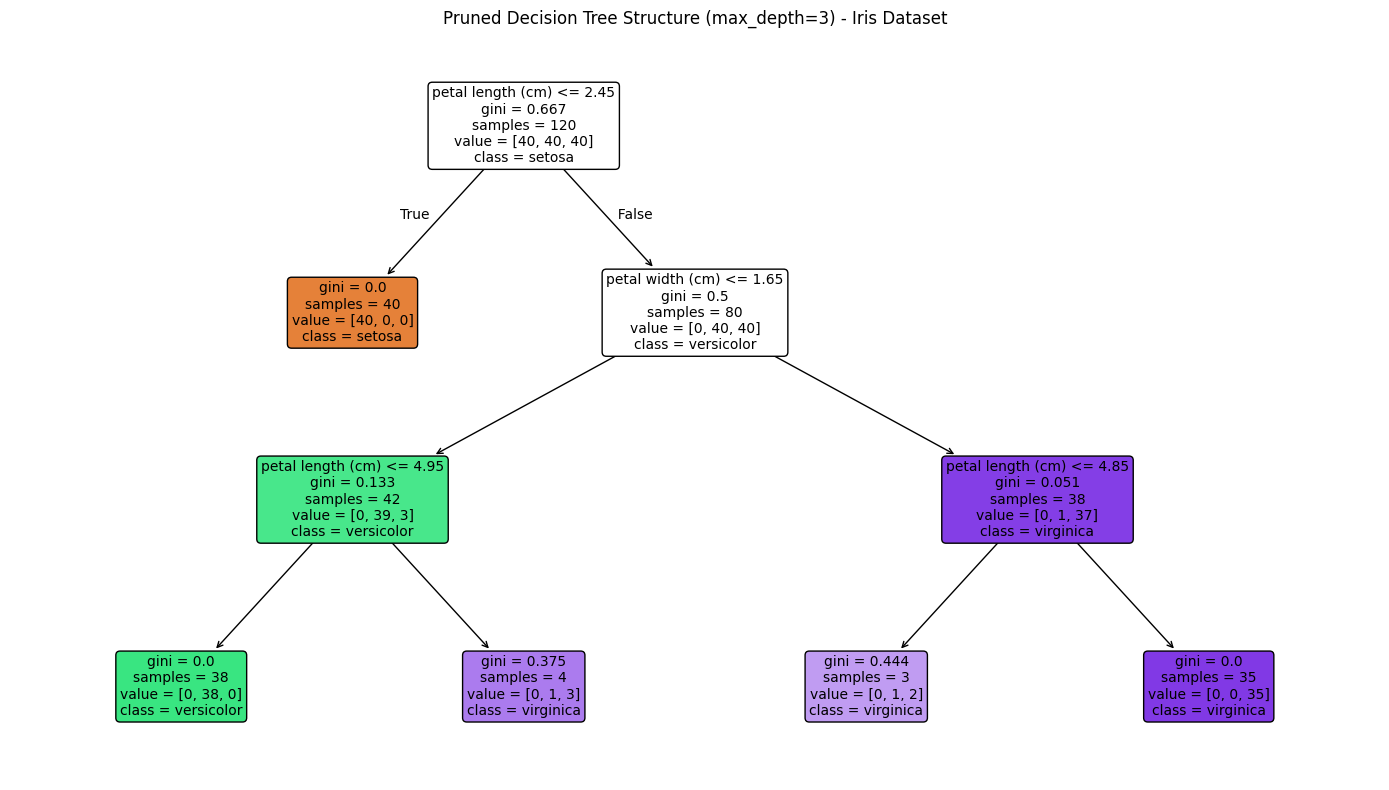

In [1]:
# ==========================================
# Codveda Technologies - Machine Learning Internship
# Level 2 (Intermediate) - Task 2: Decision Trees for Classification
# Intern: MD JUNAID KHAN
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Load Labeled Dataset (Iris Flower Dataset)
iris = load_iris(as_frame=True)
df = iris.frame
X = iris.data
y = iris.target
class_names = list(iris.target_names)

print("Dataset Shape:", df.shape)
print("Target Classes:", class_names)
print("Missing Values:", df.isnull().sum().sum())

# 2. Train-Test Split (80% Train, 20% Test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train Unpruned Decision Tree (Baseline - prone to overfitting)
unpruned_tree = DecisionTreeClassifier(random_state=42)
unpruned_tree.fit(X_train, y_train)

y_train_pred_unpruned = unpruned_tree.predict(X_train)
y_test_pred_unpruned = unpruned_tree.predict(X_test)

print("\n--- Unpruned Decision Tree ---")
print(f"Train Accuracy: {accuracy_score(y_train, y_train_pred_unpruned):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, y_test_pred_unpruned):.4f}")
print(f"Test F1-Score (weighted): {f1_score(y_test, y_test_pred_unpruned, average='weighted'):.4f}")

# 4. Prune the Decision Tree to Prevent Overfitting (max_depth=3)
pruned_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=2, random_state=42)
pruned_tree.fit(X_train, y_train)

y_train_pred_pruned = pruned_tree.predict(X_train)
y_test_pred_pruned = pruned_tree.predict(X_test)

pruned_acc = accuracy_score(y_test, y_test_pred_pruned)
pruned_f1_weighted = f1_score(y_test, y_test_pred_pruned, average='weighted')
pruned_f1_macro = f1_score(y_test, y_test_pred_pruned, average='macro')

print("\n--- Pruned Decision Tree (max_depth=3) ---")
print(f"Train Accuracy:           {accuracy_score(y_train, y_train_pred_pruned):.4f}")
print(f"Test Accuracy:            {pruned_acc:.4f}")
print(f"Test F1-Score (weighted): {pruned_f1_weighted:.4f}")
print(f"Test F1-Score (macro):    {pruned_f1_macro:.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred_pruned))
print("\nClassification Report:\n", classification_report(y_test, y_test_pred_pruned, target_names=class_names))

# 5. Visualize the Decision Tree Structure
plt.figure(figsize=(14, 8))
plot_tree(
    pruned_tree,
    feature_names=iris.feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Pruned Decision Tree Structure (max_depth=3) - Iris Dataset")
plt.tight_layout()
plt.show()